In [3]:
!pip install tensorflow

  Using cached h5py-3.14.0-cp313-cp313-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (2.7 kB)
  Using cached rich-14.1.0-py3-none-any.whl.metadata (18 kB)
  Using cached markdown_it_py-4.0.0-py3-none-any.whl.metadata (7.3 kB)
  Using cached mdurl-0.1.2-py3-none-any.whl.metadata (1.6 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 620.8/620.8 MB 15.7 MB/s  0:00:34m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.4/6.4 MB 16.9 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 13.2 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 16.1 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.6/6.6 MB 15.2 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 13.8 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 16.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.5/24.5 MB 19.7 MB/s  0:00:01m0:00:0100:01
Using cached rich-

Always run this 1st cell

In [2]:
import pandas as pd
import numpy as np
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input, Dropout
import seaborn as sns

sns.set_theme(context='notebook', style='darkgrid', palette='colorblind')

# Set seeds (obs: pandas uses Numpy)
SEED = 42
np.random.seed(SEED) 
tf.random.set_seed(SEED) 

2025-10-09 12:18:13.361256: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2025-10-09 12:18:13.919995: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2025-10-09 12:18:16.965764: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


# Crappy model 1: CM1

- Using the Dan data (removed only -9999 NaNs)


In [7]:
# Load data

#path = '150k.csv'
#df = pd.read_csv()
#df = pd.read_pickle('150k_quali-multiindex.pkl')
#df = pd.read_pickle('data_red_bruta.pkl')            # data del Dan (aún con algunos NaN)
df = pd.read_csv('cleanA_150k.csv')
df.shape

(149983, 67)

In [8]:
df

,z,zErr,dec,decErr,dered_g,dered_i,dered_r,dered_u,dered_z,deVRad_g,...,psfMag_i,psfMag_r,psfMag_u,psfMag_z,psfMagErr_g,psfMagErr_i,psfMagErr_r,psfMagErr_u,psfMagErr_z,ra
0,1.967009,0.001295,0.099945,0.004153,18.74923,18.55813,18.67467,18.87822,18.45218,0.091994,...,18.92338,19.15566,19.76303,18.72110,0.017365,0.015810,0.015986,0.029013,0.033841,57.405766
1,0.133383,0.000062,0.075584,0.009540,19.82256,18.39337,18.82100,21.98708,18.03142,0.833777,...,19.37808,19.95601,23.14468,18.83381,0.053584,0.083252,0.069951,0.343517,0.051267,57.488430
2,0.505413,0.000175,0.036211,0.036408,21.45808,18.62883,19.56389,21.53409,18.04682,0.939758,...,20.09372,21.19098,23.46836,19.39700,0.149051,0.025049,0.041548,0.401160,0.053212,57.590708
3,1.248642,0.000341,0.971539,0.012089,20.41834,20.08604,19.99310,20.21941,20.27955,0.230714,...,20.20711,20.18484,20.56856,20.31880,0.037061,0.045533,0.028918,0.050030,0.120847,44.283683
4,0.066696,0.000006,1.047021,0.015802,19.00809,18.25147,18.56176,19.90209,18.13738,1.461907,...,19.12809,19.55080,21.05799,18.91005,0.019690,0.023346,0.018100,0.068637,0.039914,49.275599
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
149978,0.523190,0.000102,56.332271,0.039700,21.26369,18.45656,19.38538,23.55142,17.99068,2.787953,...,19.47815,20.38832,24.53234,19.02971,0.108178,0.022276,0.038616,0.875940,0.045896,141.116087
149979,0.508194,0.000221,61.501827,0.044107,22.25257,19.64563,20.59183,22.66739,19.18695,3.709756,...,20.54820,21.43578,23.25575,20.00042,0.156003,0.046724,0.055938,0.410539,0.105663,225.231674
149980,0.234232,0.000044,61.015388,0.012894,18.94200,17.13919,17.64632,20.86497,16.80165,4.772612,...,19.02218,19.42988,22.61482,18.63499,0.027229,0.018064,0.016232,0.230208,0.036420,226.317436
149981,0.352076,0.000068,60.126007,0.015690,20.67480,18.40559,19.04279,22.63412,17.99781,1.564977,...,19.36206,19.97786,23.25273,18.96493,0.050867,0.023696,0.025761,0.385661,0.046441,228.298076


In [33]:
# Separate features (X) and target (y)
X = df.drop('z', axis=1)
y = df['z']

print("Data loaded and seeds set.")

# --- 3. DATA PREPROCESSING (SPLIT and STANDARDIZATION) ---
# 60-20-20 split

# 3.1. Train-Test Split (e.g., 80% Train/Val, 20% Test)
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED
)

# 3.2. Train-Validation Split (e.g., 75% of 80% = 60% Train, 25% of 80% = 20% Val)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.25, random_state=SEED     # 0.25 * 0.8 = 0.2 for validation
)

# 3.3. Standardization (fit only on X_train, then transform all)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print(f"Data split: Train ({len(X_train)}), Validation ({len(X_val)}), Test ({len(X_test)}) samples.")
print("Data standardized.")

# --- 4. MODEL DEFINITION WITH HYPER-PARAMETERS ---

def build_fnn_model(input_shape, hidden_layers_units, activation='relu', output_activation='linear', optimizer='adam'):
    """
    Builds a Fully Connected Feed-Forward Neural Network.

    Args:
        input_shape (int): Number of features (input dimension).
        hidden_layers_units (list of int): Units in each hidden layer.
        activation (str): Activation function for hidden layers.
        output_activation (str): Activation function for the output layer (linear for regression).
        optimizer (str): Optimization algorithm.

    Returns:
        tf.keras.Model: The compiled Keras model.
    """
    model = Sequential()
    # Input Layer (implicitly defined by the first Dense layer or explicitly with Input)
    model.add(Input(shape=(input_shape,)))

    # Hidden Layers
    for units in hidden_layers_units:
        model.add(Dense(units, activation=activation))

    # Output Layer (1 unit for scalar target)
    model.add(Dense(1, activation=output_activation))

    # Compile the model (using MSE for a regression task)
    model.compile(optimizer=optimizer, loss='mse', metrics=['mae'])
    return model

# --- HYPER-PARAMETERS ---
HP_INPUT_SHAPE = X_train_scaled.shape[1]
HP_HIDDEN_LAYERS_UNITS = [32, 16, 8] # Architecture: 3 hidden layers with 64, 32, and 16 units
HP_ACTIVATION = 'relu'
HP_OPTIMIZER = 'adam'
HP_EPOCHS = 250
HP_BATCH_SIZE = 256

# Build the model
model = build_fnn_model(
    input_shape=HP_INPUT_SHAPE,
    hidden_layers_units=HP_HIDDEN_LAYERS_UNITS,
    activation=HP_ACTIVATION,
    optimizer=HP_OPTIMIZER
)

model.summary()

# --- 5. TRAINING ---

print("\nStarting model training...")

history = model.fit(
    X_train_scaled, y_train,
    epochs=HP_EPOCHS,
    batch_size=HP_BATCH_SIZE,
    validation_data=(X_val_scaled, y_val),
    verbose=1 # Set to 1 or 2 for progress bar
)

print("Training finished.")

Data loaded and seeds set.
Data split: Train (89989), Validation (29997), Test (29997) samples.
Data standardized.


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 32)             │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,313 (5.13 KB)

 Trainable params: 1,313 (5.13 KB)

 Non-trainable params: 0 (0.00 B)


Starting model training...
Epoch 1/250
352/352 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.2475 - mae: 0.2894 - val_loss: 0.1699 - val_mae: 0.2336
Epoch 2/250
352/352 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.1505 - mae: 0.2129 - val_loss: 0.1345 - val_mae: 0.1964
Epoch 3/250
352/352 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.1244 - mae: 0.1823 - val_loss: 0.1176 - val_mae: 0.1729
Epoch 4/250
352/352 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.1145 - mae: 0.1674 - val_loss: 0.1120 - val_mae: 0.1634
Epoch 5/250
352/352 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.1102 - mae: 0.1608 - val_loss: 0.1093 - val_mae: 0.1593
Epoch 6/250
352/352 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.1076 - mae: 0.1572 - val_loss: 0.1070 - val_mae: 0.1561
Epoch 7/250
352/352 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.1056 - mae: 0.1547 - val_loss: 0.1056 - val_mae: 0.1540
Epoch 8/250
352/352 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.1042 - mae: 0.1528 - val_loss: 0.1040 - val_mae: 0.1519
Epoch 9/250
352/352 

Test Loss (MSE): 0.0932, Test MAE: 0.1318


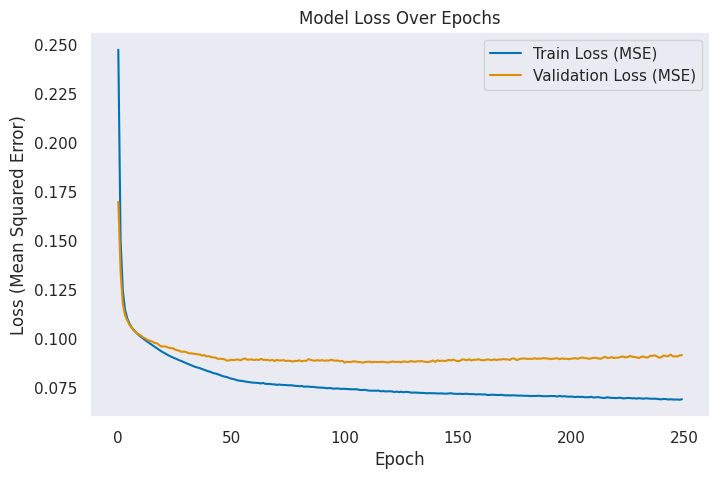

In [ ]:
# Optional: Evaluate on the test set
loss, mae = model.evaluate(X_test_scaled, y_test, verbose=0)
print(f"Test Loss (MSE): {loss:.4f}, Test MAE: {mae:.4f}")

# --- 6. VISUALIZATION ---

plt.figure(figsize=(8, 5))
# Get training and validation loss values
plt.plot(history.history['loss'], label='Train Loss (MSE)')
plt.plot(history.history['val_loss'], label='Validation Loss (MSE)')

# Add title and labels
plt.title('Model Loss Over Epochs')
plt.ylabel('Loss (Mean Squared Error)')
plt.xlabel('Epoch')

# Add legend and grid
plt.legend(loc='upper right')
plt.grid()
#plt.show()

#plt.savefig('crappy2_loss.png', dpi=400)

In [35]:
# Ahora gráficar la recta 1-1 perfecta entre las predicciones y los datos reales

y_pred = model.predict(X_test_scaled)
y_pred

938/938 ━━━━━━━━━━━━━━━━━━━━ 1s 562us/step


array([[0.59327966],
       [2.0370107 ],
       [1.6347258 ],
       ...,
       [0.6266707 ],
       [2.7771134 ],
       [0.56652427]], shape=(29997, 1), dtype=float32)

In [36]:
R2_test = r2_score(y_test, y_pred)

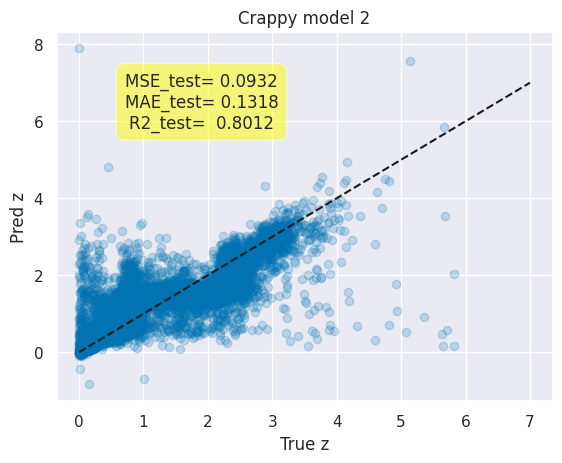

In [ ]:
fig, ax = plt.subplots()

ax.scatter(y_test, y_pred, alpha=.2)
ax.plot([0,7], [0, 7],linestyle='--', color='k')
ax.set_xlabel('True z')
ax.set_ylabel('Pred z')
ax.set_title('Crappy model 2')

ax.text(1.9, 6.5, f'MSE_test= {round(loss,4)}\nMAE_test= {round(mae,4)}\nR2_test=  {round(R2_test,4)}',
        horizontalalignment='center',
        verticalalignment='center',
        bbox=dict(facecolor='yellow', alpha=0.5, boxstyle='round,pad=0.5'))

#plt.savefig('crappymodel2.png', dpi=400)

# Crappy model 2: CM2

- Dado que nuestro modelo presenta un early overfitting, implementamos dropout
- Adicionalmente, utilizamos 

In [18]:
import pandas as pd
import numpy as np
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input, Dropout
from keras.optimizers import Adam
from data_utils import gen_rand_split

# --- 1. LOAD DATA ---
df_raw = pd.read_csv('cleanA_150k.csv')

# --- 2. SEED SETTING FOR REPRODUCIBILITY ---
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("Data loaded and seeds set.")

Data loaded and seeds set.


In [15]:
# --- 3. DATA PREPROCESSING (SPLIT and STANDARDIZATION) ---
val_p, test_p = 0.2, 0.15  
X_train, X_val, X_test, y_train, y_val, y_test = gen_rand_split(df_raw, val_p, test_p, SEED=42)

# 3.3. Standardization (fit only on X_train, then transform all)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print(f"Data split: Train ({len(X_train)}), Validation ({len(X_val)}), Test ({len(X_test)}) samples.")
print("Data standardized.")

Data split: Train (97488), Validation (29997), Test (22498) samples.
Data standardized.


In [16]:
# -------------------------------------------------------------
# --- 4. MODEL DEFINITION WITH DROPOUT (MODIFIED SECTION) ---
# -------------------------------------------------------------
#units_l1, units_l2, units_l3
# 
def build_fnn_model_with_dropout(input_shape, units_hl, rates_dl, activation, output_activation='linear', optimizer='adam', lr=1e-3):
    """
    Builds a Fully Connected FF NN with explicit Dropout layers.
    This structure is unrolled for clarity and specific dropout placement.
    """
    model = Sequential()
    
    # Input Layer (Input shape defined here)
    model.add(Input(shape=(input_shape,)))
    
    # Hidden Layer 1
    model.add(Dense(units_hl[0], activation=activation[0], name='Hidden_1'))
    # Dropout after L1
    model.add(Dropout(rates_dl[0], name='Dropout_1')) 
    
    # Hidden Layer 2
    model.add(Dense(units_hl[1], activation=activation[1], name='Hidden_2'))
    # Dropout after L2
    model.add(Dropout(rates_dl[1], name='Dropout_2'))
    
    # Hidden Layer 3
    model.add(Dense(units_hl[2], activation=activation[2], name='Hidden_3'))
    
    # Output Layer (1 unit for scalar target/regression)
    model.add(Dense(1, activation=output_activation, name='Output_Layer'))

    # Define optimizer
    if optimizer=='adam':
        opt = Adam(learning_rate=lr)
    else:
        opt = 'adam'        

    # Compile the model
    model.compile(optimizer=opt, loss='mse', metrics=['mae'])
    return model

# --- HYPER-PARAMETERS (MODIFIED TO INCLUDE DROPOUT RATES) ---
HP_INPUT_SHAPE = X_train_scaled.shape[1]
# Units for each layer
#HP_UNITS_L1 = 64
#HP_UNITS_L2 = 32
#HP_UNITS_L3 = 16
UNITS_HL = [96, 64, 16] 
# Dropout Rates
RATES_DL = [0.3, 0.2]  
# Other HPs
HP_ACTIVATION = ['relu', 'relu', 'relu']   # ['prelu', 'prelu', 'prelu']
HP_OPTIMIZER = 'adam'
HP_LR = 1e-3
HP_EPOCHS = 250
HP_BATCH_SIZE = 128

# Build the model
model = build_fnn_model_with_dropout(
    input_shape=HP_INPUT_SHAPE,
    units_hl=UNITS_HL,
    rates_dl=RATES_DL,
    activation=HP_ACTIVATION,
    optimizer=HP_OPTIMIZER
)

model.summary()         # save

# -------------------------------------------------------------
# --- 5. TRAINING ---
# -------------------------------------------------------------

print("\nStarting model training...")

history = model.fit(
    X_train_scaled, y_train,
    epochs=HP_EPOCHS,
    batch_size=HP_BATCH_SIZE,
    validation_data=(X_val_scaled, y_val),
    verbose=0
)

print("Training finished.")

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Hidden_1 (Dense)                │ (None, 96)             │         6,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dropout_1 (Dropout)             │ (None, 96)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Hidden_2 (Dense)                │ (None, 64)             │         6,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Hidden_3 (Dense)                │ (None, 16)             │         1,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Output_Layer (Dense)            │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,697 (53.50 KB)

 Trainable params: 13,697 (53.50 KB)

 Non-trainable params: 0 (0.00 B)


Starting model training...
Training finished.


Test Loss (MSE): 0.0667, Test MAE: 0.1024


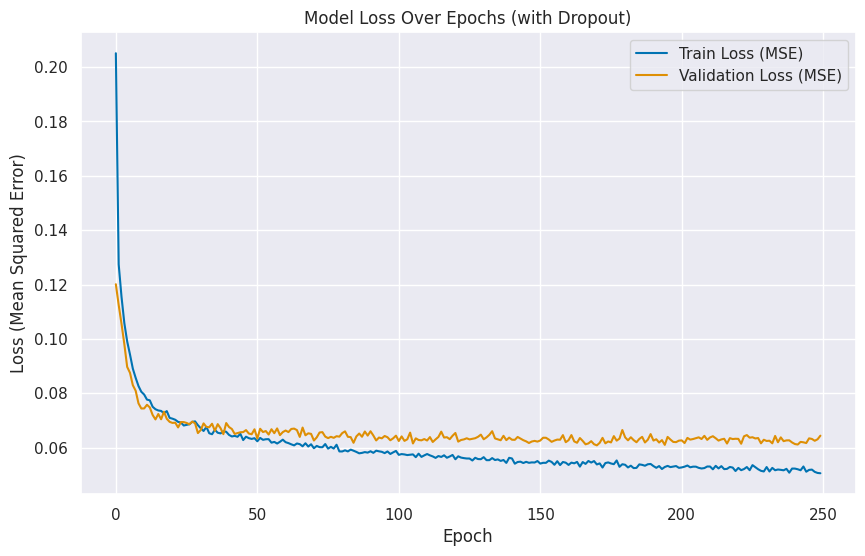

In [17]:
# Optional: Evaluate on the test set
loss, mae = model.evaluate(X_test_scaled, y_test, verbose=0)
print(f"Test Loss (MSE): {loss:.4f}, Test MAE: {mae:.4f}")

# -------------------------------------------------------------
# --- 6. VISUALIZATION ---
# -------------------------------------------------------------

plt.figure(figsize=(10, 6))
# Get training and validation loss values
plt.plot(history.history['loss'], label='Train Loss (MSE)')
plt.plot(history.history['val_loss'], label='Validation Loss (MSE)')

# Add title and labels
plt.title('Model Loss Over Epochs (with Dropout)')
plt.ylabel('Loss (Mean Squared Error)')
plt.xlabel('Epoch')

# Add legend and gridFeatures
plt.legend(loc='upper right')
plt.grid(True)
plt.show()

Tiene algo de potencial

In [ ]:
# little test
# Guardar función de pérdida en entrenamiento y validación
train_losses = history.history['loss'] 
val_losses = history.history['val_loss']

In [61]:
y_pred = pd.Series(y_pred.flatten())

,Mean,Variance,Skewness,Kurtosis
True z,0.626819,0.466512,2.214449,5.334682
Pred z,0.608428,0.346853,1.927073,4.059794


# Crappy model 3: CM3

- We pick some of the features based on physical arguments
- Features: 
    - dered_u, dered_g, dered_r, dered_i, dered_z
    - 

# Crappy model 4: CM4

- Implement PCA
- 

# 5

In [19]:
import os
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

In [20]:
import pandas as pd
import numpy as np
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input, Dropout
from keras.optimizers import Adam
from data_utils import gen_rand_split

# --- 1. LOAD DATA ---
df_raw = pd.read_csv('cleanA_150k.csv')

# --- 2. SEED SETTING FOR REPRODUCIBILITY ---
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("Data loaded and seeds set.")

Data loaded and seeds set.


In [21]:
# --- 3. DATA PREPROCESSING (SPLIT and STANDARDIZATION) ---
val_p, test_p = 0.2, 0.15  
X_train, X_val, X_test, y_train, y_val, y_test = gen_rand_split(df_raw, val_p, test_p, SEED=42)

# 3.3. Standardization (fit only on X_train, then transform all)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print(f"Data split: Train ({len(X_train)}), Validation ({len(X_val)}), Test ({len(X_test)}) samples.")
print("Data standardized.")

Data split: Train (97488), Validation (29997), Test (22498) samples.
Data standardized.


In [22]:
# -------------------------------------------------------------
# --- 4. MODEL DEFINITION WITH DROPOUT (MODIFIED SECTION) ---
# -------------------------------------------------------------
#units_l1, units_l2, units_l3
# 
def build_fnn_model_with_dropout(input_shape, units_hl, rates_dl, activation, output_activation='linear', optimizer='adam', lr=1e-3):
    """
    Builds a Fully Connected FF NN with explicit Dropout layers.
    This structure is unrolled for clarity and specific dropout placement.
    """
    model = Sequential()
    
    # Input Layer (Input shape defined here)
    model.add(Input(shape=(input_shape,)))
    
    # Hidden Layer 1
    model.add(Dense(units_hl[0], activation=activation[0], name='Hidden_1'))
    # Dropout after L1
    model.add(Dropout(rates_dl[0], name='Dropout_1')) 
    
    # Hidden Layer 2
    model.add(Dense(units_hl[1], activation=activation[1], name='Hidden_2'))
    # Dropout after L2
    model.add(Dropout(rates_dl[1], name='Dropout_2'))
    
    # Hidden Layer 3
    model.add(Dense(units_hl[2], activation=activation[2], name='Hidden_3'))
    
    # Output Layer (1 unit for scalar target/regression)
    model.add(Dense(1, activation=output_activation, name='Output_Layer'))

    # Define optimizer
    if optimizer=='adam':
        opt = Adam(learning_rate=lr)
    else:
        opt = 'adam'        

    # Compile the model
    model.compile(optimizer=opt, loss='mse', metrics=['mae'])
    return model

# --- HYPER-PARAMETERS (MODIFIED TO INCLUDE DROPOUT RATES) ---
HP_INPUT_SHAPE = X_train_scaled.shape[1]
# Units for each layer
#HP_UNITS_L1 = 64
#HP_UNITS_L2 = 32
#HP_UNITS_L3 = 16
UNITS_HL = [96, 64, 16] 
# Dropout Rates
RATES_DL = [0.3, 0.2]  
# Other HPs
HP_ACTIVATION = ['relu', 'relu', 'relu']   # ['prelu', 'prelu', 'prelu']
HP_OPTIMIZER = 'adam'
HP_LR = 1e-3
HP_EPOCHS = 4
HP_BATCH_SIZE = 64

# Build the model
model = build_fnn_model_with_dropout(
    input_shape=HP_INPUT_SHAPE,
    units_hl=UNITS_HL,
    rates_dl=RATES_DL,
    activation=HP_ACTIVATION,
    optimizer=HP_OPTIMIZER
)

model.summary()         # save

# -------------------------------------------------------------
# --- 5. TRAINING ---
# -------------------------------------------------------------

print("\nStarting model training...")

history = model.fit(
    X_train_scaled, y_train,
    epochs=HP_EPOCHS,
    batch_size=HP_BATCH_SIZE,
    validation_data=(X_val_scaled, y_val),
    verbose=0
)

print("Training finished.")

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Hidden_1 (Dense)                │ (None, 96)             │         6,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dropout_1 (Dropout)             │ (None, 96)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Hidden_2 (Dense)                │ (None, 64)             │         6,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Hidden_3 (Dense)                │ (None, 16)             │         1,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Output_Layer (Dense)            │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,697 (53.50 KB)

 Trainable params: 13,697 (53.50 KB)

 Non-trainable params: 0 (0.00 B)


Starting model training...
Training finished.


In [28]:
# Optional: Evaluate on the test set
loss, mae = model.evaluate(X_test_scaled, y_test, verbose=0)
print(f"Test Loss (MSE): {loss:.4f}, Test MAE: {mae:.4f}")

# -------------------------------------------------------------
# --- 6. VISUALIZATION ---
# -------------------------------------------------------------
'''
plt.figure(figsize=(10, 6))
# Get training and validation loss values
plt.plot(history.history['loss'], label='Train Loss (MSE)')
plt.plot(history.history['val_loss'], label='Validation Loss (MSE)')

# Add title and labels
plt.title('Model Loss Over Epochs (with Dropout)')
plt.ylabel('Loss (Mean Squared Error)')
plt.xlabel('Epoch')

# Add legend and gridFeatures
plt.legend(loc='upper right')
plt.grid(True)
plt.show()
'''

Test Loss (MSE): 0.0886, Test MAE: 0.1381


"\nplt.figure(figsize=(10, 6))\n# Get training and validation loss values\nplt.plot(history.history['loss'], label='Train Loss (MSE)')\nplt.plot(history.history['val_loss'], label='Validation Loss (MSE)')\n\n# Add title and labels\nplt.title('Model Loss Over Epochs (with Dropout)')\nplt.ylabel('Loss (Mean Squared Error)')\nplt.xlabel('Epoch')\n\n# Add legend and gridFeatures\nplt.legend(loc='upper right')\nplt.grid(True)\nplt.show()\n"

In [27]:
'''
# --- HYPER-PARAMETERS (MODIFIED TO INCLUDE DROPOUT RATES) ---
HP_INPUT_SHAPE = X_train_scaled.shape[1]
# Units for each layer
UNITS_HL = [96, 64, 16] 
# Dropout Rates
RATES_DL = [0.3, 0.2]               # add 0s were there's no dropout  
# Other HPs
HP_ACTIVATION = ['relu', 'relu', 'relu']   # ['prelu', 'prelu', 'prelu']
HP_OPTIMIZER = 'adam'
HP_LR = 1e-3
HP_EPOCHS = 250
HP_BATCH_SIZE = 128
'''
# Define things for this particular model
loss_str = 'mse'
Seed = SEED
standariz_method = 'StandardScaler'
transformation = 'None'
train_losses = history.history['loss']
val_losses = history.history['val_loss']
X_test_df = pd.DataFrame(X_test_scaled)       # to df
y_pred = model.predict(X_test_scaled)
predictions_df = pd.DataFrame(y_pred)              #y_pred = model.predict(X_test_scaled)
R2_test = r2_score(y_test, y_pred)


704/704 ━━━━━━━━━━━━━━━━━━━━ 0s 533us/step


In [49]:
# Solicitar el nombre del modelo al usuario
model_name = input("Por favor, introduce el nombre del modelo (Ej: Coby_v1): ")

# Definir la ruta base: Resultados/NOMBRE_DEL_MODELO
BASE_PATH = os.path.join('Resultados', model_name)
os.makedirs(BASE_PATH, exist_ok=True)

print(f"\nGuardando resultados críticos en: '{BASE_PATH}'")

# 1. Archivo de Descripción (README)
readme_content = f"""# Registro del Experimento: {model_name}

## Configuración Principal
- Arquitectura: Coby (5 capas densas con ReLU con 128 N)
- Neuronas: {UNITS_HL}
- Activaciones: {HP_ACTIVATION}
- Dropouts: {RATES_DL }                      
- Transformacion: {transformation}
- Estandarizacion: {standariz_method}
- Nombre del Modelo: {model_name}
- Loss: {loss_str}
- Semilla global (SEED): {Seed}
- Dimensión de Entrada (in_dim): {HP_INPUT_SHAPE}
- Epoch: {HP_EPOCHS}
- Bach_size: {HP_BATCH_SIZE}
- Optimizador: {HP_OPTIMIZER} 
- Learn_rate: {HP_LR}
"""

# Guardar README en la carpeta del modelo
with open(os.path.join(BASE_PATH, 'README.md'), 'w') as f:
    f.write(readme_content)
print("- README.md (Descripción) guardado.")

# 2. Resultados (Métricas)
results_data = {
    'Metric': ['RMSE', 'MSE', 'MAE', 'R2'],
    'Value': [np.sqrt(loss), loss, mae, R2_test]            # [-150:]
}

results_df = pd.DataFrame(results_data)
# Guardar CSV de métricas en la carpeta del modelo
results_df.to_csv(os.path.join(BASE_PATH, 'metrics.csv'), index=False)
print("- metrics.csv (Métricas) guardado.")

# 3. Momentos con agg o stats
moments_test = X_test_df.agg(['mean', 'var', 'skew', 'kurt'])
moments_pred = predictions_df.agg(['mean', 'var', 'skew', 'kurt'])
moments_df = pd.concat([moments_test, moments_pred])           #      moments_test.concat(moments_pred)
moments_df.to_csv(os.path.join(BASE_PATH, 'moments.csv'), index=False)
print("- moments.csv (Momentos) guardado.")

# 5. Gráfica de Entrenamiento (Train/Val Loss)
plt.figure(figsize=(10, 6))
plt.plot(train_losses, label='Train Loss')
plt.plot(val_losses, label='Validation Loss')
plt.title('Pérdida de Entrenamiento y Validación por Época')
plt.xlabel('Época')
plt.ylabel('Pérdida')
plt.legend()
plt.grid(True)
plt.savefig(os.path.join(BASE_PATH, 'train_val_loss.png'), dpi=300)
plt.close()
print("- train_val_loss.png (Gráfica de Pérdida) guardado.")

residuals = y_pred.flatten()-y_test.values
# Gráfica de Análisis de Residuales (Residuales vs Predichos)
plt.figure(figsize=(10, 6))
plt.scatter(y_pred.flatten(), residuals, alpha=0.4)
plt.axhline(y=0, color='r', linestyle='--')
plt.title('Residuos vs. Predicciones')
plt.xlabel('Predicciones')
plt.ylabel('Residuos (y_pred - y_true)')
plt.grid(True, linestyle=':', alpha=0.7)
plt.savefig(os.path.join(BASE_PATH, 'Prediccion.png'), dpi=300)
plt.close()
print("- Prediccion.png (Residuales vs Predicciones) guardado")

# Gráfica de Distribución de Residuales (Histograma/KDE)
plt.figure(figsize=(8, 5))
sns.kdeplot(residuals, color='purple',fill=True, alpha=0.6)
plt.title('Distribución de Frecuencia de los Residuales')
plt.xlabel('Residuales (Error)')
plt.ylabel('Frecuencia')
plt.axvline(x=0, color='r', linestyle='--')
plt.savefig(os.path.join(BASE_PATH, 'Dist_residuos.png'), dpi=300)
plt.close()
print("- Dist_residuos.png (Distribución de Residuales) guardado")

print("\nProceso finalizado. Solo los resultados clave fueron guardados.")
     
# Agregar algún violin or box plot



Guardando resultados críticos en: 'Resultados/ss'
- README.md (Descripción) guardado.
- metrics.csv (Métricas) guardado.
- moments.csv (Momentos) guardado.
- train_val_loss.png (Gráfica de Pérdida) guardado.
- Prediccion.png (Residuales vs Predicciones) guardado.
- Dist_residuos.png (Distribución de Residuales) guardado.

Proceso finalizado. Solo los resultados clave fueron guardados.


In [43]:
y_pred, residuals

(array([[0.53341514],
        [1.8383633 ],
        [1.6238354 ],
        ...,
        [0.5011484 ],
        [0.21401891],
        [0.60361135]], shape=(22498, 1), dtype=float32),
 array([[ 0.02205094, -0.29494426, -1.03745786, ..., -0.00553776,
          0.5277444 , -0.09083396],
        [ 1.32699909,  1.01000389,  0.26749029, ...,  1.29941039,
          1.83269255,  1.21411419],
        [ 1.11247124,  0.79547604,  0.05296244, ...,  1.08488254,
          1.6181647 ,  0.99958634],
        ...,
        [-0.0102158 , -0.327211  , -1.0697246 , ..., -0.0378045 ,
          0.49547766, -0.1231007 ],
        [-0.29734529, -0.61434049, -1.35685409, ..., -0.32493399,
          0.20834817, -0.41023019],
        [ 0.09224715, -0.22474805, -0.96726165, ...,  0.06465845,
          0.59794061, -0.02063775]], shape=(22498, 22498)))

- Now just tidy up everthing here 
- To handle non-dropout layers just pass a list of the same dimension as the activation and units ones, but fill with zeros the
layers that don't use dropout. Use this snippet: 

```python
# Loop through the hidden layers
for i in range(len(units_hl)):
    # 1. Add the Dense (Hidden) Layer
    model.add(Dense(units=units_hl[i], 
                    activation=activation[i], 
                    name=f'Hidden_{i+1}'))
    
    # 2. Conditionally Add the Dropout Layer
    # Only add the layer if the rate is > 0
    if rates_dl[i] > 0.0:
        model.add(Dropout(rate=rates_dl[i], 
                          name=f'Dropout_{i+1}'))

``` 

# Model T1A

- Primera prueba de implementación completa del sistema de guardado general
- Ver model_launcher